# B — Logistic regression and decision tree
## tl;dr
This executed companion reads the completed training experiment and independently reproduces validation predictions from saved pipelines. It does not silently rerun the hyperparameter search or evaluate test.

## Context & Methods
Logistic regression models linear log-odds with L2 regularization: a useful interpretable baseline, but limited for nonlinear interactions. A decision tree recursively partitions features by impurity reduction: it captures interactions but can overfit; depth and minimum leaf size control complexity.

### Key Assumptions
Same fixed train folds, AP selection, and fold-local balanced weights for all families. Validation metrics use p≥0.5 and are development diagnostics. Three-fold SD is not a confidence interval. D chooses thresholds and conducts the final test. Total search: 36 configurations across four families, 108 base CV fits.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from src.data import load_partition, audit_data
from src.metrics import binary_metrics
import joblib
EXPERIMENT = ROOT / 'results/experiment'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

## Data
The original 11 fields enter an importable pipeline; exact `pdays` becomes prior-contact status. Scaling is used for LR/MLP.
No learned transformation is fitted outside each CV training subset.

In [2]:
X_val,y_val=load_partition('val')
print('Validation records:',len(y_val),'(not final test)')

Validation records: 9042 (not final test)


### Inspect the actual model constructor and search space

In [3]:
from src.models import search_configs,build_model
from src.training import fit_candidate
import inspect
names=['logistic_regression', 'decision_tree']
for name in names:
    print(name)
    display(pd.DataFrame([{k: ('None' if v is None else v) for k,v in cfg.items()} for cfg in search_configs(name)]))
print(inspect.getsource(build_model))

logistic_regression


,C,weight
0,0.01,None
1,0.01,balanced
2,0.10,None
3,0.10,balanced
4,1.00,None
5,1.00,balanced
6,10.00,None
7,10.00,balanced


decision_tree


,max_depth,min_samples_leaf,weight
0,4,100,None
1,4,100,balanced
2,4,20,None
3,4,20,balanced
4,8,100,None
5,8,100,balanced
6,8,20,None
7,8,20,balanced
8,None,100,None
9,None,100,balanced


def build_model(name, config, *, iteration_cap=None):
    params = {k: v for k, v in config.items() if k != 'weight'}
    if name == 'logistic_regression':
        model = LogisticRegression(solver='lbfgs', max_iter=2000, random_state=42, **params)
    elif name == 'decision_tree':
        model = DecisionTreeClassifier(criterion='gini', random_state=42, **params)
    elif name == 'random_forest':
        model = RandomForestClassifier(n_estimators=200, max_features='sqrt', bootstrap=True,
                                       random_state=42, n_jobs=1, **params)
    elif name == 'mlp':
        model = MLPClassifier(activation='relu', solver='adam', learning_rate_init=.001,
                              batch_size=256, early_stopping=False, max_iter=iteration_cap or 300,
                              tol=1e-4, n_iter_no_change=20, random_state=42, **params)
    elif name == 'dummy':
        model = DummyClassifier(strategy='prior')
    else:
        raise ValueError(name)
    return P

### Reproduce training explicitly
From the project root with the supplied environment:
```powershell
.venv\Scripts\python.exe scripts/train.py --output results/rerun --jobs 2
```
The output directory must be new. This command reruns all fixed configurations and records every fold, warning and refit. It produces no test predictions or performance metrics; the source CSV is read for structural checks.
Below, the completed `results/experiment` is inspected to keep notebook execution fast and deterministic.

## Results
### Selected parameters and training-fold scores

In [4]:
metadata={}
for name in names:
    metadata[name]=json.loads((EXPERIMENT/name/'model_metadata.json').read_text(encoding='utf-8'))
    print(name,metadata[name]['selected_params'])
    table=pd.read_csv(EXPERIMENT/name/'cv_candidates.csv')
    display(table[['config_id','mean_average_precision','std_average_precision','mean_train_ap','unconverged_folds']].rename(columns={
        'mean_average_precision':'CV AP mean','std_average_precision':'CV AP SD',
        'mean_train_ap':'Train AP','unconverged_folds':'Unconverged folds'}).round(5))

logistic_regression {'C': 0.1, 'weight': None}


,config_id,CV AP mean,CV AP SD,Train AP,Unconverged folds
0,0,0.33700,0.00888,0.34024,0
1,1,0.33781,0.00940,0.34082,0
2,2,0.34187,0.00933,0.34554,0
3,3,0.34057,0.00928,0.34373,0
4,4,0.34159,0.00990,0.34557,0
5,5,0.34058,0.00969,0.34342,0
6,6,0.34155,0.00992,0.34558,0
7,7,0.34057,0.00980,0.34342,0


decision_tree {'max_depth': None, 'min_samples_leaf': 100, 'weight': None}


,config_id,CV AP mean,CV AP SD,Train AP,Unconverged folds
0,0,0.29453,0.00553,0.30311,0
1,1,0.28559,0.00668,0.29963,0
2,2,0.29119,0.00489,0.30753,0
3,3,0.28404,0.00833,0.30317,0
4,4,0.33450,0.00644,0.36342,0
5,5,0.33168,0.00597,0.36250,0
6,6,0.32513,0.00574,0.39422,0
7,7,0.33007,0.00900,0.39075,0
8,8,0.33579,0.00844,0.38173,0
9,9,0.33273,0.00539,0.37812,0


### Reload and verify all validation predictions

In [5]:
metric_rows=[]
for name in names:
    model=joblib.load(EXPERIMENT/name/'pipeline.joblib')
    with threadpool_limits(limits=1):
        p=model.predict_proba(X_val)[:,1]
    saved=pd.read_csv(EXPERIMENT/name/'validation_predictions.csv')
    np.testing.assert_array_equal(saved.row_id.to_numpy(),X_val.index.to_numpy())
    np.testing.assert_array_equal(saved.y_true.to_numpy(),y_val.to_numpy())
    np.testing.assert_allclose(saved.p_yes,p,rtol=1e-12,atol=1e-12)
    metric_rows.append({'model':name,**binary_metrics(y_val,p)})
metrics=pd.DataFrame(metric_rows).set_index('model')
display(metrics[['average_precision','roc_auc','precision','recall','f1','accuracy']].rename(columns={
    'average_precision':'AP','roc_auc':'ROC-AUC','precision':'Precision','recall':'Recall','f1':'F1','accuracy':'Accuracy'}).round(5))
display(metrics[['tn','fp','fn','tp','brier_score','log_loss']].rename(columns={
    'brier_score':'Brier score','log_loss':'Log loss'}).round(5))
print('All saved validation rows, labels and probabilities reproduced.')

,AP,ROC-AUC,Precision,Recall,F1,Accuracy
model,,,,,,
logistic_regression,0.35887,0.72097,0.70356,0.16824,0.27155,0.89438
decision_tree,0.36983,0.72478,0.70229,0.17391,0.27879,0.89471


,tn,fp,fn,tp,Brier score,Log loss
model,,,,,,
logistic_regression,7909,75,880,178,0.08937,0.31522
decision_tree,7906,78,874,184,0.08839,0.34078


All saved validation rows, labels and probabilities reproduced.


### Training versus CV tuning diagnostics

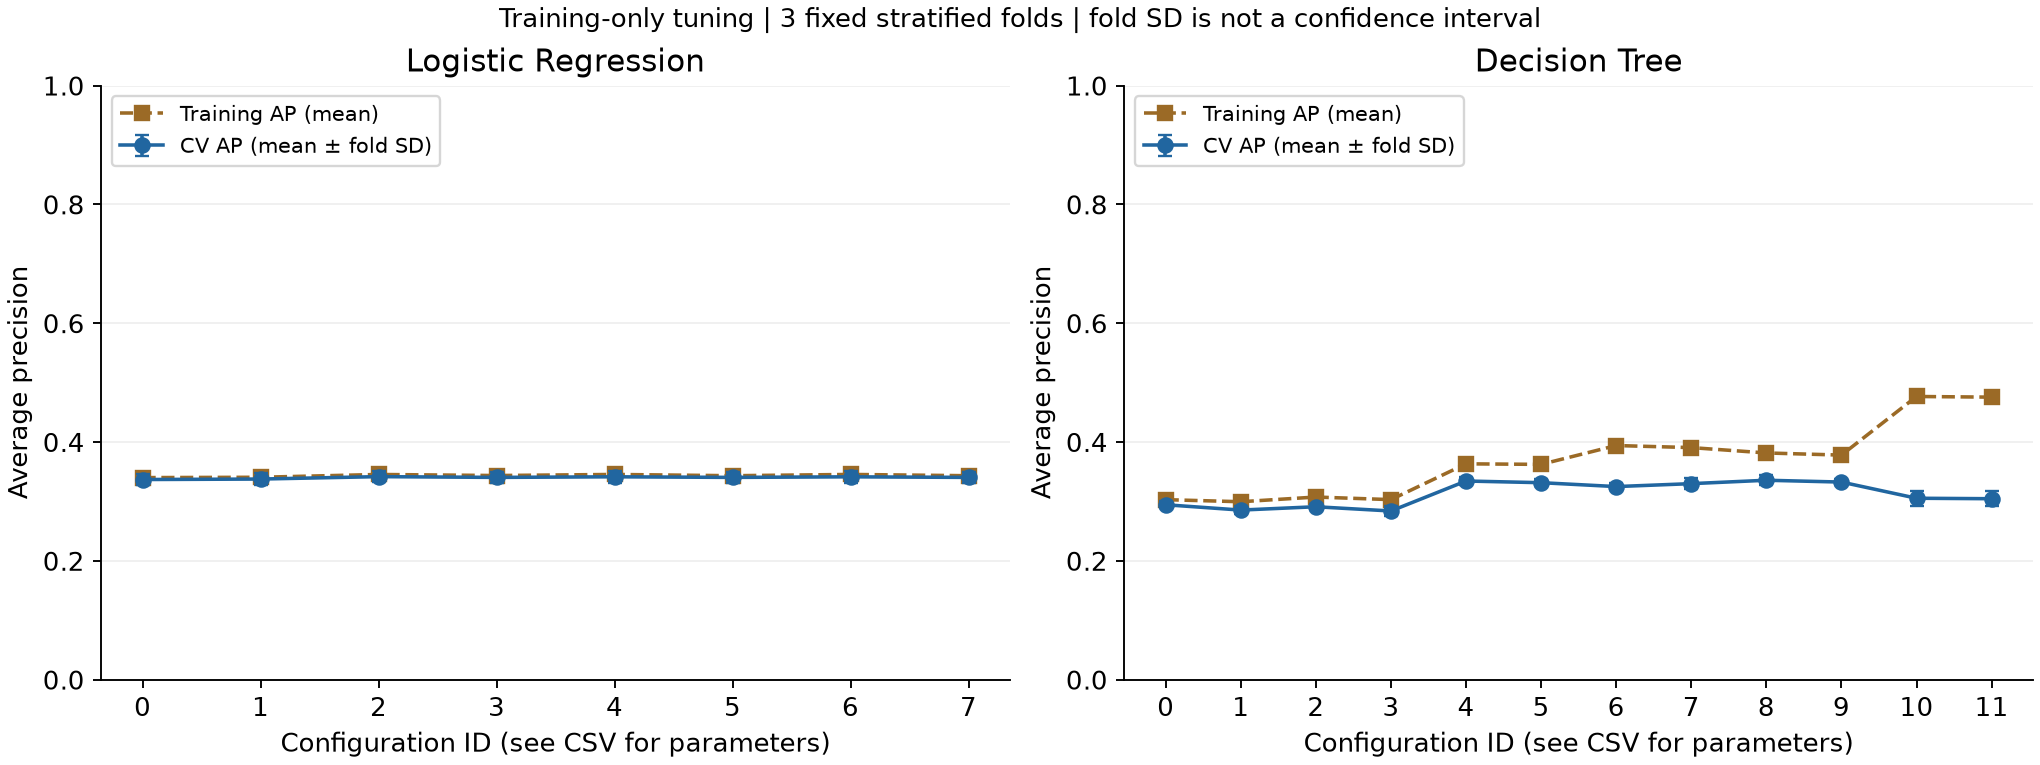

In [6]:
from src.model_plots import generate_model_plots
generate_model_plots(EXPERIMENT)
display(Image(filename=str(EXPERIMENT/'figures/B_baselines_tuning.png')))

## Takeaways
The tables show the results actually produced by the frozen experiment. A larger training-to-CV AP gap is evidence of overfitting under this protocol, not proof of future failure.
Weighted model outputs are not assumed to be calibrated probabilities; 0.5 is a comparison convention rather than an optimized business threshold.
The complete model and validation CSV are ready for D. D retains threshold selection, test evaluation, error analysis, feature importance and final cross-model conclusions.
中文交接：这里的成绩属于开发阶段；不要改名为测试集成绩，也不要据此补调参数。